In [1]:
import rebound as rb
import celmech as cm
import numpy as np
from matplotlib import pyplot as plt

# Integrator options

This example notebook is designed to show how to set options related to the integration of equations of motion inc `celmech`. We'll start by writing a function atha tinitializes a Hamiltonian to model a 3:2 MMR between a pair of planets.

In [2]:
def get_hamiltonian():
    sim = rb.Simulation()
    sim.add(m=1)
    sim.add(m=1e-4,P =1)
    sim.add(m=1e-5,P =3/2,e=0.04,pomega = np.pi)
    pvars = cm.Poincare.from_Simulation(sim)
    pham = cm.PoincareHamiltonian(pvars)
    pham.add_MMR_terms(3,1)
    return pham

### Default settings

Now we'll get a Hamiltonian and integrate the equations of motion, starting with the default settings.

By default, `celmech`'s [`Hamiltonian`](https://celmech.readthedocs.io/en/latest/hamiltonian.html) class, including the sub-class [`PoincareHamiltonian`](https://celmech.readthedocs.io/en/latest/poincare.html#module-celmech.poincare), rely on `scipy.integrate`'s [`ode`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.ode.html) class and uses the `vode` integrator. By default the integrator method is set to `method='adams'` and the relative tolerance is set to `rtol=1e-14`. Each Hamiltonian instance owns an `integrator` attribute:

In [3]:
pham = get_hamiltonian()
integrator = pham.integrator
print(integrator)

You can view the various settings of the integrator as follows:

In [4]:
vars(integrator._integrator)

{'meth': 1,
 'with_jacobian': False,
 'rtol': 1e-14,
 'atol': 1e-12,
 'mu': None,
 'ml': None,
 'order': 12,
 'nsteps': 500,
 'max_step': 0.0,
 'min_step': 0.0,
 'first_step': 0.0,
 'success': 1,
 'initialized': False,
 'rwork': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0.]),
 'iwork': array([  0,   0,   0,   0,  12, 500,   2,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0], dtype=int32),
 'call_args': [1e-14,
  1e-12,
  1,
  1,
  array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0.]),
  array([  0,   0,   0,   0,  12, 500,   2,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
     

Now lets integrate!

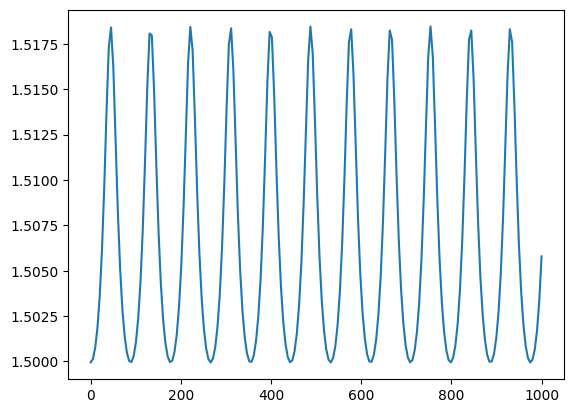

In [5]:
times =  np.linspace(0,1e3,200)
Pout_default = np.zeros(times.shape[0]) # Period of the outer planet
for i,t in enumerate(times):
    pham.integrate(t)
    Pout_default[i] = pham.particles[2].P
plt.plot(times,Pout_default)

### Changing integrator settings

We can modify the default settings with `Hamiltonian.set_integrator` method, which is really just a shortcut for the underlying `ode` object's [`set_integrator` method](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.ode.set_integrator.html#scipy.integrate.ode.set_integrator). The method take's the integrator name along with keyword arguemnts. Let's try switching the integration method to `BDF`.

In [6]:
pham.set_integrator('vode',method='BDF')

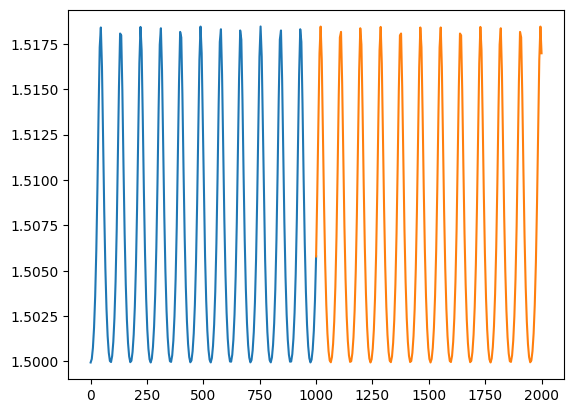

In [7]:
times_new = pham.t + times
Pout_bdf = np.zeros(times_new.shape[0])
for i,t in enumerate(times_new):
    pham.integrate(t)
    Pout_bdf[i] = pham.particles[2].P
plt.plot(times,Pout_default)
plt.plot(times_new,Pout_bdf)

### Using your own integrator

While scipy's `ode` class supports an array of different methods, you may want to turn to some other, custom integration method. In this case, the easiest option is probably to simply use the equations of motion automatically generated by your `Hamiltonian` object and pass them to your custom integrator. These can be accessed through the `Hamiltonian.flow_func` attribute. Additionally, if your method of choice relies on the equations' Jacobian, you can use the `Hamiltonian.jacobian_func` attribute. These methods take as arguments the values of the system's canonical variables.

In [8]:
pham = get_hamiltonian()
initial_conditions = pham.state.values
print(initial_conditions)

[0.0, -0.0, -0.0, 3.141592653589793, -1.2209688596002516e-20, -0.0, 5.419129345039056e-05, 1.3386833487371913e-07, 0.0, 6.203409971628536e-06, -9.96996734446485e-05, 0.0]


Note that `flow_func` and `jacobian_func` take individual arguments rather than an array. Arrays can be easily conveted to individual arguments by 'splatting' (i.e., prefixing a `*` to a collection) as shown:

In [9]:
pham.flow_func(*initial_conditions)

array([[ 6.28301392e+00],
       [-7.15133114e-07],
       [ 0.00000000e+00],
       [ 4.18894063e+00],
       [ 2.59230036e-06],
       [ 0.00000000e+00],
       [-1.26675065e-25],
       [ 2.62735644e-22],
       [ 0.00000000e+00],
       [ 1.90012597e-25],
       [-9.52395703e-22],
       [ 0.00000000e+00]])

In [10]:
pham.jacobian_func(*initial_conditions)

array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        -3.47824172e+05,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 5.25471288e-22,  0.00000000e+00,  0.00000000e+00,
        -7.88206931e-22,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        -2.02579258e+06,  0.00000000e+00,  0.00000000e+00],
       [-1.90479141e-21,  0.00000000e+00,  0.0000000

The example below uses `scipy.integrate`'s `solve_ivp` as a custom integrator and relies on the implicity `Radau` scheme. `lambda` functions are used in order to provide `solve_ivp` with the types of arguments this function expects.

Plotting Lambda1 versus time:


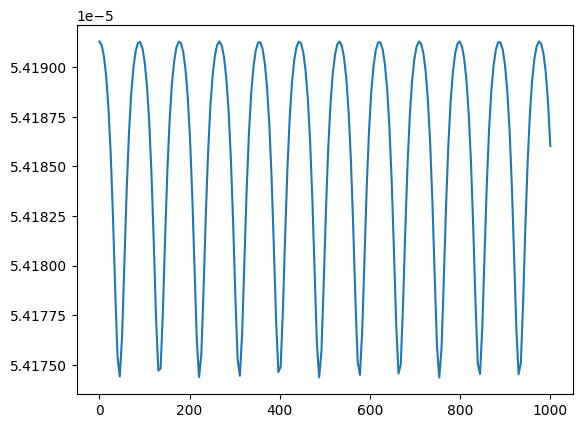

In [11]:
from scipy.integrate import solve_ivp
f = lambda t,x: pham.flow_func(*x).reshape(-1)
Df = lambda t,x: pham.jacobian_func(*x)
soln = solve_ivp(
    f,
    (times[0],times[-1]),
    initial_conditions,
    method='Radau',
    t_eval=times,
    jac = Df,
    rtol = 1e-8,
    atol = 1e-6
)
print(f"Plotting {pham.qp_vars[pham.N_dof]} versus time:")
plt.plot(soln.t,soln.y[pham.N_dof])

Now we'll convert `solve_ivp`'s time series of canonical variables to orbital elements by settting the `pham.state.values` attribute.

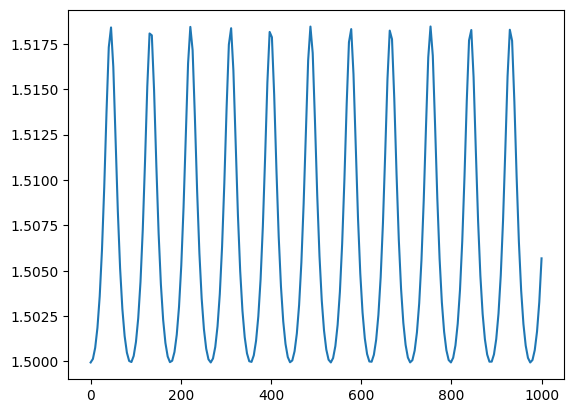

In [12]:
Pout_radau = np.zeros(times_new.shape[0])
for i,sol in enumerate(soln.y.T):
    pham.state.values = sol
    Pout_radau[i] = pham.particles[2].P

plt.plot(soln.t,Pout_radau)